# Week 3 - Wednesday: GridSearchCV
Dataset: **Breast Cancer** (built into scikit-learn, no CSV needed). 569 samples, 30 numeric features, target: malignant (0) or benign (1).

Plan for today:
1. Split off a test set that the search never sees
2. Build Pipelines (scaler + classifier) and score the **default** models
3. Tune **kNN**, **Decision Tree** and **Logistic Regression** with `GridSearchCV`
4. Read `best_params_`, `best_score_` and `cv_results_`
5. Compare default vs tuned on the **held-out test set**

## Parameters vs hyperparameters
- **Parameters** are *learned* by the model from the data (weights in logistic regression, split points in a tree).
- **Hyperparameters** are *set by you* before training (`n_neighbors` in kNN, `max_depth` in a tree, `C` in logistic regression).

`GridSearchCV` tries **every combination** in a grid you define, scores each one with cross-validation, and reports the best.

## 1. Imports and data

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, f1_score, classification_report

sns.set_style("whitegrid")
RANDOM_STATE = 42

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print("Shape:", X.shape)
print("Classes (0 = malignant, 1 = benign):")
print(y.value_counts().sort_index())

Shape: (569, 30)
Classes (0 = malignant, 1 = benign):
target
0    212
1    357
Name: count, dtype: int64


## 2. Hold out a test set first
The test set is split off **before** any tuning and is used **once**, at the end. If we tuned on it, the final score would be too optimistic, because the search would have already "seen" it.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)

# The same 5 folds for every search, so results are comparable
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (455, 30)  Test: (114, 30)


## 3. Default models in a Pipeline (the baseline)

In [16]:
def make_pipe(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

defaults = {
    "kNN": make_pipe(KNeighborsClassifier()),
    "Decision Tree": make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=5000)),
}

baseline = {}
for name, pipe in defaults.items():
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv)
    pipe.fit(X_train, y_train)
    baseline[name] = {
        "default_cv_mean": cv_scores.mean(),
        "default_cv_std": cv_scores.std(),
        "default_test_acc": accuracy_score(y_test, pipe.predict(X_test)),
    }
pd.DataFrame(baseline).T.round(4)

,default_cv_mean,default_cv_std,default_test_acc
kNN,0.9626,0.0112,0.9561
Decision Tree,0.9165,0.0179,0.9123
Logistic Regression,0.9780,0.0098,0.9825


The scaler is **inside** the Pipeline, so during cross-validation it is re-fitted on each training fold only. This avoids data leakage.

Parameter names inside a Pipeline use the step name and two underscores: `model__n_neighbors`, `model__max_depth`, `model__C`.

## 4. GridSearchCV on kNN

In [17]:
knn_grid = {
    "model__n_neighbors": list(range(1, 31)),
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"],
}

knn_search = GridSearchCV(make_pipe(KNeighborsClassifier()), knn_grid,
                          cv=cv, scoring="accuracy", n_jobs=-1)
knn_search.fit(X_train, y_train)

print("Combinations tried:", len(knn_search.cv_results_["params"]))
print("Best params:", knn_search.best_params_)
print("Best CV score (best_score_):", round(knn_search.best_score_, 4))

Combinations tried: 120
Best params: {'model__metric': 'manhattan', 'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best CV score (best_score_): 0.9714


In [18]:
# cv_results_ as a table: top 10 combinations
def top_results(search, n=10):
    res = pd.DataFrame(search.cv_results_)
    cols = ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    return res[cols].sort_values("rank_test_score").head(n)

top_results(knn_search).round(4)

,params,mean_test_score,std_test_score,rank_test_score
65,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9714,0.0132,1
64,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9714,0.0132,1
23,"{'model__metric': 'euclidean', 'model__n_neigh...",0.9692,0.0128,3
22,"{'model__metric': 'euclidean', 'model__n_neigh...",0.9692,0.0128,3
67,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9692,0.0128,3
66,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9692,0.0162,3
18,"{'model__metric': 'euclidean', 'model__n_neigh...",0.9692,0.0128,3
71,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9670,0.0251,8
72,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9670,0.0251,8
73,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9670,0.0251,8


**How to read this:**
- `best_score_` is the **mean CV accuracy** of the best combination on the training data. It is not the test score.
- `std_test_score` is the spread across the 5 folds. If the top combinations differ by less than this spread, they are effectively tied, and the "best" one may just be lucky.

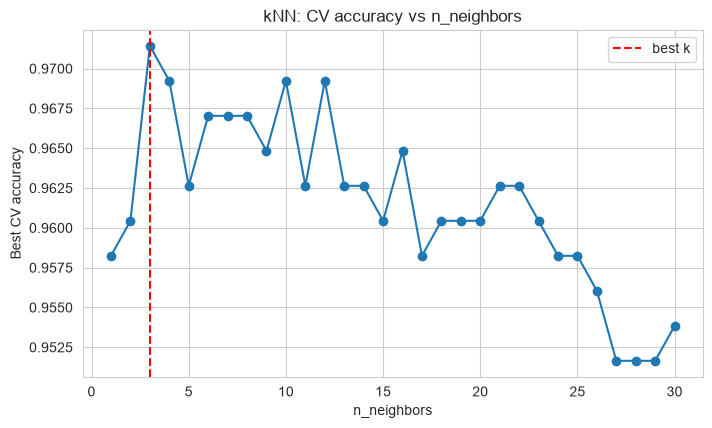

In [19]:
# Picture: CV accuracy vs n_neighbors (best of the other settings at each k)
res = pd.DataFrame(knn_search.cv_results_)
res["n_neighbors"] = res["param_model__n_neighbors"].astype(int)
by_k = res.groupby("n_neighbors")["mean_test_score"].max()

plt.figure(figsize=(8, 4.5))
plt.plot(by_k.index, by_k.values, "o-")
plt.axvline(knn_search.best_params_["model__n_neighbors"], color="red", linestyle="--", label="best k")
plt.xlabel("n_neighbors"); plt.ylabel("Best CV accuracy")
plt.title("kNN: CV accuracy vs n_neighbors"); plt.legend(); plt.show()

## 5. GridSearchCV on Decision Tree

In [20]:
tree_grid = {
    "model__max_depth": [1, 2, 3, 4, 5, 6, 8, 10, None],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__criterion": ["gini", "entropy"],
}

tree_search = GridSearchCV(make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                           tree_grid, cv=cv, scoring="accuracy", n_jobs=-1)
tree_search.fit(X_train, y_train)

print("Combinations tried:", len(tree_search.cv_results_["params"]))
print("Best params:", tree_search.best_params_)
print("Best CV score:", round(tree_search.best_score_, 4))
top_results(tree_search).round(4)

Combinations tried: 72
Best params: {'model__criterion': 'entropy', 'model__max_depth': 4, 'model__min_samples_leaf': 5}
Best CV score: 0.9363


,params,mean_test_score,std_test_score,rank_test_score
50,"{'model__criterion': 'entropy', 'model__max_de...",0.9363,0.0189,1
5,"{'model__criterion': 'gini', 'model__max_depth...",0.9319,0.0189,2
14,"{'model__criterion': 'gini', 'model__max_depth...",0.9319,0.0162,2
4,"{'model__criterion': 'gini', 'model__max_depth...",0.9319,0.0189,2
44,"{'model__criterion': 'entropy', 'model__max_de...",0.9319,0.0235,2
45,"{'model__criterion': 'entropy', 'model__max_de...",0.9319,0.0235,2
46,"{'model__criterion': 'entropy', 'model__max_de...",0.9319,0.0235,2
10,"{'model__criterion': 'gini', 'model__max_depth...",0.9319,0.0162,2
48,"{'model__criterion': 'entropy', 'model__max_de...",0.9319,0.0162,9
12,"{'model__criterion': 'gini', 'model__max_depth...",0.9297,0.0149,10


## 6. GridSearchCV on Logistic Regression (optional third model)

In [21]:
lr_grid = {"model__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

lr_search = GridSearchCV(make_pipe(LogisticRegression(max_iter=5000)),
                         lr_grid, cv=cv, scoring="accuracy", n_jobs=-1)
lr_search.fit(X_train, y_train)

print("Best params:", lr_search.best_params_)
print("Best CV score:", round(lr_search.best_score_, 4))
top_results(lr_search, n=7).round(4)

Best params: {'model__C': 0.1}
Best CV score: 0.9824


,params,mean_test_score,std_test_score,rank_test_score
2,{'model__C': 0.1},0.9824,0.0054,1
3,{'model__C': 1},0.9780,0.0098,2
4,{'model__C': 10},0.9626,0.0112,3
5,{'model__C': 100},0.9538,0.0162,4
1,{'model__C': 0.01},0.9516,0.0149,5
6,{'model__C': 1000},0.9473,0.0162,6
0,{'model__C': 0.001},0.8857,0.0292,7


**Edge of the grid:** if the best value sits at the very edge of your grid (for example the smallest or largest `C`, or `max_depth` at the maximum), the true best may lie outside it. Widen the grid and search again.

## 7. Before vs after, on the held-out test set

In [22]:
searches = {"kNN": knn_search, "Decision Tree": tree_search, "Logistic Regression": lr_search}

rows = []
for name, s in searches.items():
    tuned = s.best_estimator_           # already refitted on the full training set
    default = defaults[name]            # fitted earlier in section 3
    best_idx = s.best_index_
    rows.append({
        "model": name,
        "default_cv": baseline[name]["default_cv_mean"],
        "tuned_cv": s.best_score_,
        "tuned_cv_std": s.cv_results_["std_test_score"][best_idx],
        "default_test_acc": accuracy_score(y_test, default.predict(X_test)),
        "tuned_test_acc": accuracy_score(y_test, tuned.predict(X_test)),
        "tuned_test_recall_malignant": recall_score(y_test, tuned.predict(X_test), pos_label=0),
        "best_params": s.best_params_,
    })

results = pd.DataFrame(rows).set_index("model")
results.round(4)

,default_cv,tuned_cv,tuned_cv_std,default_test_acc,tuned_test_acc,tuned_test_recall_malignant,best_params
model,,,,,,,
kNN,0.9626,0.9714,0.0132,0.9561,0.9649,0.9286,"{'model__metric': 'manhattan', 'model__n_neigh..."
Decision Tree,0.9165,0.9363,0.0189,0.9123,0.8772,0.9286,"{'model__criterion': 'entropy', 'model__max_de..."
Logistic Regression,0.9780,0.9824,0.0054,0.9825,0.9737,0.9524,{'model__C': 0.1}


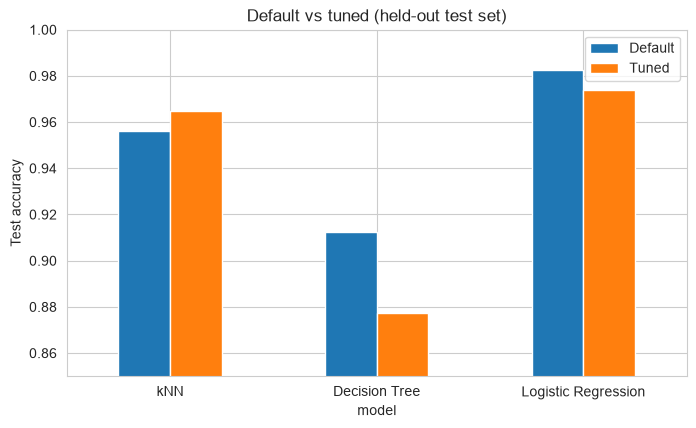

In [23]:
plot_df = results[["default_test_acc", "tuned_test_acc"]]
plot_df.plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.ylim(0.85, 1.0)
plt.ylabel("Test accuracy")
plt.title("Default vs tuned (held-out test set)")
plt.legend(["Default", "Tuned"])
plt.show()

In [24]:
# Choose the model by CV score (not by test score, or the test set stops being untouched)
best_name = results["tuned_cv"].idxmax()
print("Best tuned model by CV score:", best_name)
print(classification_report(y_test, searches[best_name].best_estimator_.predict(X_test),
                            target_names=["malignant", "benign"]))

Best tuned model by CV score: Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [25]:
print(knn_search.best_params_)
print(tree_search.best_params_)

{'model__metric': 'manhattan', 'model__n_neighbors': 3, 'model__weights': 'uniform'}
{'model__criterion': 'entropy', 'model__max_depth': 4, 'model__min_samples_leaf': 5}


**Things to notice and write down:**
1. Did tuning improve the **test** score, and by how much? Compare the gain with `tuned_cv_std`. A gain smaller than the spread may just be noise.
2. The test set only has about 114 samples, so one extra correct prediction changes accuracy by roughly 0.9 percentage points. Do not over-read small differences.
3. For Breast Cancer, **recall on the malignant class** matters most, because a missed malignant case is the costly mistake. Check `tuned_test_recall_malignant`.
4. Is any best value on the edge of its grid?
5. Was the gain worth the compute? Count the combinations tried (grid size x 5 folds).
6. **Tuning can look better in CV but not on the test set.** In a test run, all three tuned models had a higher CV score than the default, but the tuned Decision Tree and Logistic Regression scored *lower* on the test set than their defaults. This happens: the search picks the combination that is luckiest on the CV folds, and the small test set is noisy. Report both numbers honestly, and do not go back and re-tune using the test set.

## Optional: try Wine
Change the data loading line to `from sklearn.datasets import load_wine` and use `load_wine(as_frame=True)`, then re-run everything. Wine has 3 classes, so use `pos_label` only for the Breast Cancer recall cell (replace it with `average="macro"` or remove it).